# IND320 Project Work, Part 3

**Student:** Sara Christine Gjerløw  

- **GitHub repository:** https://github.com/SaraGjerlow/ind320-SaraGjerlow  
- **Streamlit app:** https://ind320-saragjerlow.streamlit.
- **Screencast:** https://youtu.be/3ka5Xrt00hE

This part adds weather data. I sample locations inside the NVE areas, download
historical weather from open-meteo for those locations, and look for outliers
and patterns in precipitation, temperature and reservoir filling.

## 1. Imports and database connection

The MongoDB connection string is read from secrets.toml, which is gitignored
and never reaches GitHub.

In [1]:
import tomllib
from pathlib import Path
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from pymongo.mongo_client import MongoClient
from pymongo.server_api import ServerApi
from scipy.fft import dct, idct
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
import requests_cache

In [2]:
# Read the connection string from the file that stays out of GitHub.
with open(Path("../.streamlit/secrets.toml"), "rb") as f:
    secrets = tomllib.load(f)

mongo_uri = secrets["mongo"]["uri"]

# Ping the server, so a broken connection shows up here and not later.
mongo_client = MongoClient(mongo_uri, server_api=ServerApi("1"))

try:
    mongo_client.admin.command("ping")
    print("Connected to MongoDB.")
except Exception as error:
    print(error)

Connected to MongoDB.


In [3]:
# Responses are saved to disk, so nothing is ever downloaded twice.
session = requests_cache.CachedSession(".openmeteo_cache", expire_after=-1)

## 2. Sampling locations from the NVE shapefiles

Open-meteo wants coordinates, but Magasinstatistikk reports by area. So I draw
1000 random points inside each area from NVE's shapefiles and use those as
download locations.

NVE has five regions while Magasinstatistikk reports three watercourse areas,
so Sør and Øst are merged into one and Midt and Nord into another. That is
also why VASS 4 never shows up in the data, which I noticed in part 2.

In [4]:
SHAPEFILE_DIR = Path("../shapefiles")
POINTS_PER_AREA = 1000
RANDOM_STATE = 42

# NVE's five regions grouped into the three areas Magasinstatistikk reports.
REGION_TO_VASS = {"RS": 1, "RØ": 1, "RV": 2, "RM": 3, "RN": 3}


def sample_points(polygons, area_type):
    """Draw random points inside each polygon and return them as a table.

    The shapefiles use UTM coordinates in metres, so the points are converted
    to latitude and longitude, which is what open-meteo expects.
    """
    points = polygons["geometry"].sample_points(
        size=POINTS_PER_AREA, rng=RANDOM_STATE
    )
    points = points.to_crs(epsg=4326)

    # Each polygon gives one multipoint, so it is unpacked into single rows.
    rows = []
    for index, multipoint in points.items():
        area_number = polygons.loc[index, "area_number"]
        for point in multipoint.geoms:
            rows.append({
                "area_type": area_type,
                "area_number": int(area_number),
                "latitude": round(point.y, 4),
                "longitude": round(point.x, 4),
            })

    return pd.DataFrame(rows)


# The encoding has to be given, or the Norwegian letters come out wrong.
el_areas = gpd.read_file(
    SHAPEFILE_DIR / "Budområder/Budområder.shp", encoding="utf-8"
)

# The areas are named "NO 1" to "NO 5", so the number is cut out of the name.
el_areas["area_number"] = el_areas["budomr"].str.replace("NO ", "").astype(int)
el_points = sample_points(el_areas, "EL")

vass_areas = gpd.read_file(
    SHAPEFILE_DIR / "NVE_Region/NVE_Region.shp", encoding="utf-8"
)
vass_areas["area_number"] = vass_areas["REGION"].map(REGION_TO_VASS)

# Merge the regions two and two, so the points cover the whole area.
vass_areas = vass_areas.dissolve(by="area_number", as_index=False)
vass_points = sample_points(vass_areas, "VASS")

points = pd.concat([el_points, vass_points], ignore_index=True)

print("Points per area:")
print(points.groupby(["area_type", "area_number"]).size())
points.head()

Points per area:
area_type  area_number
EL         1              1000
           2              1000
           3              1000
           4              1000
           5              1000
VASS       1              1000
           2              1000
           3              1000
dtype: int64


,area_type,area_number,latitude,longitude
0,EL,1,60.7744,9.5723
1,EL,1,61.4410,11.3065
2,EL,1,61.2529,8.1826
3,EL,1,62.0135,11.5315
4,EL,1,61.3560,10.6569


1000 points in each of the eight areas, 8000 in total. The first rows are EL
1, and they land between 60 and 62 degrees north and 8 and 11 degrees east,
which is eastern Norway. So the coordinate conversion worked.

## 3. Store the sampled points in MongoDB

The app needs the same coordinates. Reading the shapefiles there would mean
installing geopandas on Streamlit Cloud, which is heavy and slow to build, so
the points go into MongoDB and the app reads them from there.

In [5]:
database = mongo_client["ind320"]
collection = database["area_points"]

# Empty it first, so running the notebook again does not duplicate anything.
collection.delete_many({})

# MongoDB stores dictionaries, and to_dict("records") makes one per row.
collection.insert_many(points.to_dict("records"))

print("Documents in collection:", collection.count_documents({}))

Documents in collection: 8000


## 4. Weather data from open-meteo

The function below looks up an area's coordinates in MongoDB and asks
open-meteo for hourly ERA5 weather. A thousand locations is too much for one
request, so they go in batches of 25. The series are added up as they arrive
and divided at the end, so the result is one average row per hour for the
whole area.

In [6]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

HOURLY_VARIABLES = [
    "temperature_2m",
    "precipitation",
    "snowfall",
    "relative_humidity_2m",
    "wind_speed_10m",
]

LOCATIONS_PER_REQUEST = 25


def load_area_points(area_type, area_number):
    """Read the sampled coordinates for one area back from MongoDB."""
    documents = collection.find(
        {"area_type": area_type, "area_number": area_number},
        {"_id": 0, "latitude": 1, "longitude": 1},
    )
    return pd.DataFrame(list(documents))


def fetch_batch(parameters):
    """Ask open-meteo for one batch of locations, waiting out the limits."""
    for attempt in range(6):
        response = session.get(ARCHIVE_URL, params=parameters, timeout=180)

        if response.status_code == 200:
            return response.json()

        # 429 means a limit was reached, which is a wait and not an error.
        if response.status_code == 429:
            print("   ", response.json().get("reason", "rate limited"))
            time.sleep(65)
            continue

        response.raise_for_status()

    raise RuntimeError("Gave up after repeated rate limits")


def download_weather(area_type, area_number, start_date, end_date,
                     max_locations=None):
    """Download hourly ERA5 weather for one area and average over its points.

    The area is named the way Magasinstatistikk names it, for example "EL"
    and 3. max_locations limits how many of the sampled points are used.
    """
    coordinates = load_area_points(area_type, area_number)

    if max_locations is not None:
        coordinates = coordinates.head(max_locations)

    print(f"Downloading {len(coordinates)} locations for {area_type} {area_number}")

    total = None
    count = 0

    for start in range(0, len(coordinates), LOCATIONS_PER_REQUEST):
        batch = coordinates.iloc[start:start + LOCATIONS_PER_REQUEST]

        # Several locations are sent as comma separated lists.
        parameters = {
            "latitude": ",".join(batch["latitude"].astype(str)),
            "longitude": ",".join(batch["longitude"].astype(str)),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ",".join(HOURLY_VARIABLES),
            "models": "era5",
        }

        results = fetch_batch(parameters)

        # One location gives a single object back, several give a list.
        if isinstance(results, dict):
            results = [results]

        # Add the series together instead of keeping one table per location.
        for result in results:
            hourly = pd.DataFrame(result["hourly"])
            hourly["time"] = pd.to_datetime(hourly["time"])
            hourly = hourly.set_index("time")

            if total is None:
                total = hourly
            else:
                total = total + hourly

            count += 1

        print(f"  {count} of {len(coordinates)} locations done")

    weather = total / count
    return weather.reset_index()

In [7]:
# All the analyses below use this one area and this one year.
LOCATIONS = 1000

weather_no3 = download_weather(
    "EL", 3, "2024-01-01", "2024-12-31", max_locations=LOCATIONS
)

print("Hours:", len(weather_no3))
print("Locations averaged:", LOCATIONS)
weather_no3.head()

  25 of 1000 locations done
  50 of 1000 locations done
  75 of 1000 locations done
  100 of 1000 locations done
  125 of 1000 locations done
  150 of 1000 locations done
  175 of 1000 locations done
  200 of 1000 locations done
  225 of 1000 locations done
  250 of 1000 locations done
  275 of 1000 locations done
  300 of 1000 locations done
  325 of 1000 locations done
  350 of 1000 locations done
  375 of 1000 locations done
  400 of 1000 locations done
  425 of 1000 locations done
  450 of 1000 locations done
  475 of 1000 locations done
  500 of 1000 locations done
  525 of 1000 locations done
  550 of 1000 locations done
  575 of 1000 locations done
  600 of 1000 locations done
  625 of 1000 locations done
  650 of 1000 locations done
  675 of 1000 locations done
  700 of 1000 locations done
  725 of 1000 locations done
  750 of 1000 locations done
  775 of 1000 locations done
  800 of 1000 locations done
  825 of 1000 locations done
  850 of 1000 locations done
  875 of 1000 loc

,time,temperature_2m,precipitation,snowfall,relative_humidity_2m,wind_speed_10m
0,2024-01-01 00:00:00,-3.6390,0.0044,0.00238,70.007,24.2055
1,2024-01-01 01:00:00,-3.7795,0.0035,0.00238,69.972,24.4904
2,2024-01-01 02:00:00,-3.7528,0.0034,0.00238,69.519,24.8277
3,2024-01-01 03:00:00,-3.7885,0.0034,0.00238,69.135,24.9223
4,2024-01-01 04:00:00,-3.7317,0.0032,0.00224,68.826,25.1120


8784 hours is 366 days, so 2024 was a leap year and nothing is missing. The
first rows show around minus 3.7 degrees and almost no precipitation on New
Year's Day, which is reasonable for eastern Norway in January.

In [8]:
# A quick look at all five variables, to see that the ranges are sensible.
weather_no3.describe()

,time,temperature_2m,precipitation,snowfall,relative_humidity_2m,wind_speed_10m
count,8784,8784.000000,8784.000000,8784.000000,8784.000000,8784.000000
mean,2024-07-01 23:30:00,5.689964,0.207001,0.022589,79.143513,14.577554
min,2024-01-01 00:00:00,-11.643300,0.000000,0.000000,43.640000,3.670100
25%,2024-04-01 11:45:00,1.182275,0.015700,0.000000,74.245250,10.298050
50%,2024-07-01 23:30:00,5.357200,0.102300,0.000140,80.900000,13.490600
75%,2024-10-01 11:15:00,11.002425,0.293050,0.016660,85.559250,17.944175
max,2024-12-31 23:00:00,22.108700,2.693600,0.931840,96.066000,44.922300
std,NaN,6.672774,0.275555,0.053284,8.892404,5.679261


All five columns have 8784 values, so nothing is missing, and nothing is
physically impossible.

The median precipitation is 0.10 mm, not zero. At one location most hours are
dry, but across a thousand locations it is almost always raining somewhere.
The extremes are damped the same way, so what the analyses below find are
events covering the whole area, not local showers.



The app should not download the weather again on every rerun, so the finished
average is stored in MongoDB as well.

In [9]:
weather_collection = database["area_weather"]

# Empty this area first, so running the notebook again does not duplicate.
weather_collection.delete_many({"area_type": "EL", "area_number": 3})

# The area has to be written into every row, so the app can filter on it.
documents = []
for row in weather_no3.to_dict("records"):
    row["area_type"] = "EL"
    row["area_number"] = 3
    documents.append(row)

weather_collection.insert_many(documents)

print("Hours stored:", weather_collection.count_documents(
    {"area_type": "EL", "area_number": 3}
))

Hours stored: 8784


## 5. Outliers in precipitation (DCT and SPC)

A rainy hour in October is not unusual, but the same amount in a dry period
is. So the season has to be removed before looking for outliers.

The cosine transform splits the series into frequencies. Keeping only the
lowest ones gives the seasonal shape, and subtracting it leaves the fast
variation, here called SATV. The limits are calculated on SATV and drawn back
onto the original curve, so they follow the season instead of being two
straight lines.

The limits use the median and the median absolute deviation instead of the
mean and the standard deviation. A few very wet hours would widen an ordinary
standard deviation enough to hide inside the limits.

In [10]:
def precipitation_outliers(weather, cutoff=25, n_sigma=3.0,
                           column="precipitation"):
    """Plot precipitation with SPC limits and mark the outliers.

    cutoff is how many of the lowest frequencies count as seasonal.
    n_sigma is how far from the seasonal level a point has to be.
    """
    series = weather.set_index("time")[column]
    values = series.to_numpy()

    # Keeping only the slowest frequencies leaves the seasonal shape.
    coefficients = dct(values, norm="ortho")
    coefficients[cutoff:] = 0.0
    seasonal = idct(coefficients, norm="ortho")

    # SATV is what remains when the season is removed.
    satv = values - seasonal

    # Median and MAD, so the outliers do not widen their own limits.
    median = np.median(satv)
    mad = np.median(np.abs(satv - median))

    # 1.4826 turns MAD into the same scale as a standard deviation.
    robust_sigma = 1.4826 * mad

    distance = n_sigma * robust_sigma
    is_outlier = np.abs(satv - median) > distance

    # Add the season back, so the limits follow it instead of being straight.
    upper = seasonal + median + distance
    lower = seasonal + median - distance

    figure, axes = plt.subplots(figsize=(12, 5))
    axes.plot(series.index, values, linewidth=0.6, color="steelblue",
              label="Average precipitation")
    axes.plot(series.index, upper, linewidth=1.0, color="grey",
              label=f"SPC limits ({n_sigma} sigma)")
    axes.plot(series.index, lower, linewidth=1.0, color="grey")
    axes.scatter(series.index[is_outlier], values[is_outlier],
                 s=14, color="crimson", zorder=3, label="Outliers")

    axes.set_title(
        f"Precipitation with SPC limits (cutoff {cutoff}, {n_sigma} sigma)"
    )
    axes.set_xlabel("Time")
    axes.set_ylabel("Precipitation (mm)")
    axes.grid(alpha=0.3)
    axes.legend(fontsize=8)
    figure.autofmt_xdate()

    outliers = pd.DataFrame({
        "time": series.index[is_outlier],
        column: values[is_outlier],
    })

    print(f"Robust standard deviation: {robust_sigma:.4f}")
    print(f"Outliers: {is_outlier.sum()} of {len(values)} hours "
          f"({100 * is_outlier.mean():.2f} percent)")

    return figure, outliers

Robust standard deviation: 0.1556
Outliers: 637 of 8784 hours (7.25 percent)


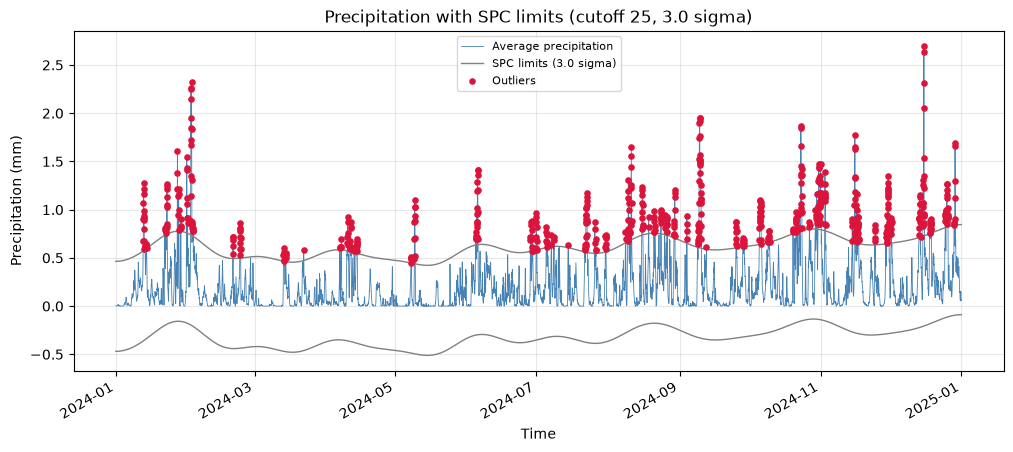


The five wettest outliers:


,time,precipitation
584,2024-12-15 18:00:00,2.6936
583,2024-12-15 17:00:00,2.6352
64,2024-02-02 18:00:00,2.3194
585,2024-12-15 19:00:00,2.3181
63,2024-02-02 17:00:00,2.2622


In [11]:
# Default settings.
figure, outliers = precipitation_outliers(weather_no3)
plt.show()

print()
print("The five wettest outliers:")
outliers.nlargest(5, "precipitation")

Robust standard deviation: 0.1640
Outliers: 196 of 8784 hours (2.23 percent)


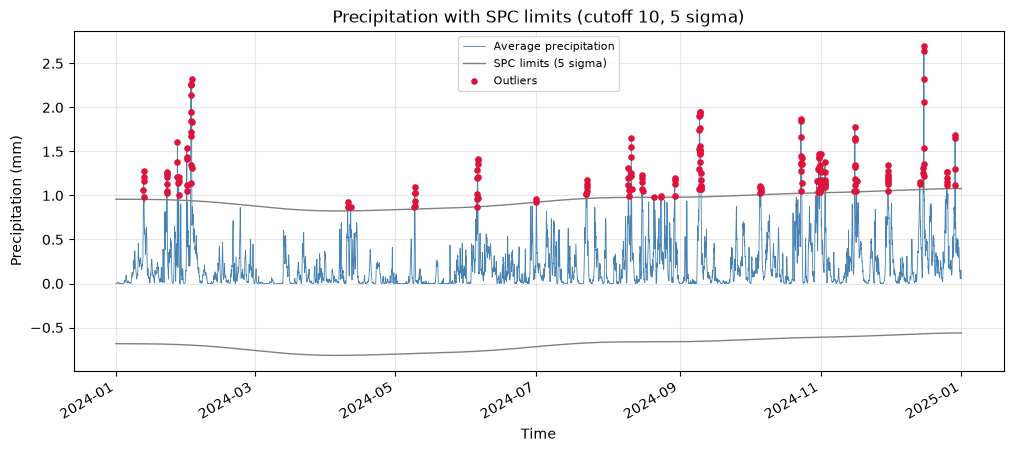

In [12]:
# A stricter limit and a smoother seasonal curve give fewer outliers.
figure, strict_outliers = precipitation_outliers(weather_no3, cutoff=10,
                                                 n_sigma=5)
plt.show()

The default settings flag 7.25 percent of the hours, which is far too many to
call outliers. Raising the limit to 5 sigma and smoothing the seasonal curve
with a cutoff of 10 brings it down to 2.23 percent.

The five wettest hours are not spread around. Three of them are consecutive
hours on 15 December and two on 2 February, so the method is picking up single
storms rather than scattered strange hours.

One thing I noticed in the plot: the limits are symmetric around the seasonal
level, so the lower one ends up below zero. Precipitation cannot be negative,
so in practice only the upper limit ever flags anything. I kept both to show
the method as it is.

## 6. Anomalies in temperature (LOF)

Local Outlier Factor does not draw a boundary. It compares how tightly packed
each point is against its neighbours, so a point sitting alone in a thin area
gets a high score even if its value is not extreme on its own.

It is given two features, the time and the temperature, both scaled so neither
dominates the distance. That makes "unusual" mean unusual for that part of the
year rather than cold or warm in general.

LOF has no natural threshold, so instead of a limit I tell it what share of
the points to flag.

In [13]:
def temperature_anomalies(weather, proportion=0.01, n_neighbors=20,
                          column="temperature_2m"):
    """Plot temperature and mark anomalies found by Local Outlier Factor.

    proportion is the share of points to flag, so 0.01 marks one percent.
    n_neighbors is how many nearby points each point is compared against.
    """
    series = weather.set_index("time")[column]
    values = series.to_numpy()

    # Time has to be a number before any distance can be calculated.
    hours = np.arange(len(values), dtype=float)

    # Both features are scaled, or the hours dominate the temperature.
    features = np.column_stack([
        (hours - hours.mean()) / hours.std(),
        (values - values.mean()) / values.std(),
    ])

    detector = LocalOutlierFactor(
        n_neighbors=n_neighbors, contamination=proportion
    )
    labels = detector.fit_predict(features)

    # fit_predict marks the anomalies with -1.
    is_anomaly = labels == -1

    # A higher score means the point is more isolated from its neighbours.
    score = -detector.negative_outlier_factor_

    figure, axes = plt.subplots(figsize=(12, 5))
    axes.plot(series.index, values, linewidth=0.6, color="steelblue",
              label="Average temperature")
    axes.scatter(series.index[is_anomaly], values[is_anomaly],
                 s=14, color="crimson", zorder=3, label="Anomalies")

    axes.set_title(
        f"Temperature with LOF anomalies ({100 * proportion:.1f} percent flagged)"
    )
    axes.set_xlabel("Time")
    axes.set_ylabel("Temperature (degrees C)")
    axes.grid(alpha=0.3)
    axes.legend(fontsize=8)
    figure.autofmt_xdate()

    anomalies = pd.DataFrame({
        "time": series.index[is_anomaly],
        column: values[is_anomaly],
        "lof_score": score[is_anomaly].round(3),
    })

    print(f"Anomalies: {is_anomaly.sum()} of {len(values)} hours "
          f"({100 * is_anomaly.mean():.2f} percent)")
    print(f"Coldest flagged: {anomalies[column].min():.1f} degrees")
    print(f"Warmest flagged: {anomalies[column].max():.1f} degrees")

    return figure, anomalies

Anomalies: 88 of 8784 hours (1.00 percent)
Coldest flagged: -10.8 degrees
Warmest flagged: 20.9 degrees


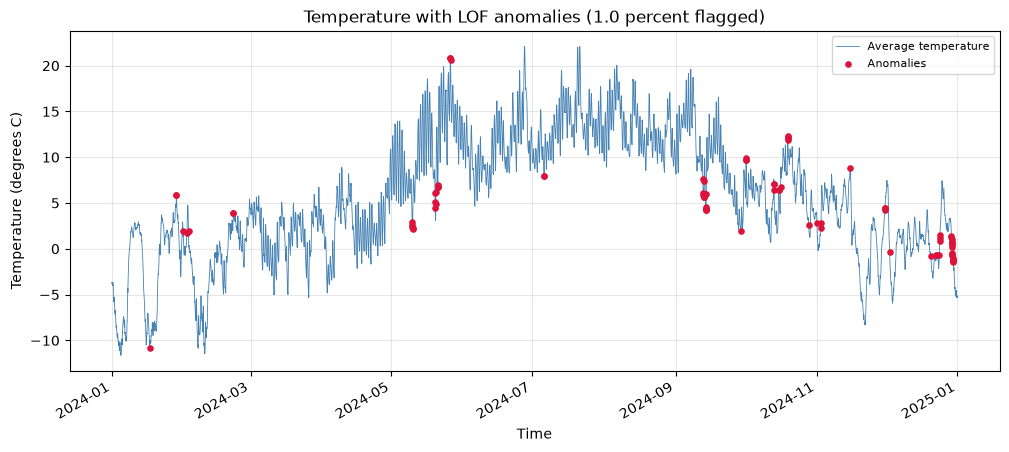


The five most isolated points:


,time,temperature_2m,lof_score
51,2024-10-19 13:00:00,12.3341,2.603
81,2024-12-29 21:00:00,-0.9750,2.574
79,2024-12-29 19:00:00,-0.6553,2.531
52,2024-10-19 14:00:00,12.2520,2.470
80,2024-12-29 20:00:00,-0.7178,2.457


In [14]:
# One percent flagged, the default.
figure, anomalies = temperature_anomalies(weather_no3)
plt.show()

print()
print("The five most isolated points:")
anomalies.nlargest(5, "lof_score")

Anomalies: 264 of 8784 hours (3.01 percent)
Coldest flagged: -10.8 degrees
Warmest flagged: 20.9 degrees


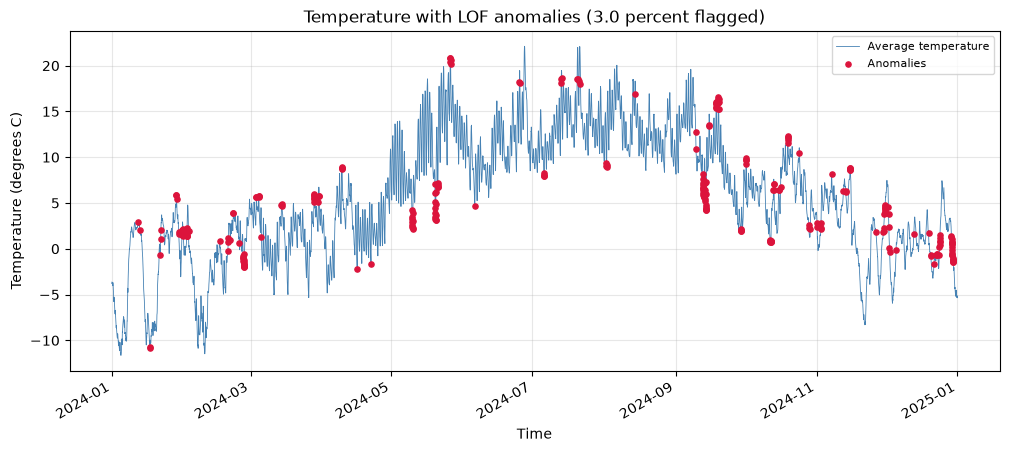

In [15]:
# Raising the proportion flags more, including shorter events.
figure, more_anomalies = temperature_anomalies(weather_no3, proportion=0.03)
plt.show()

The share comes out exactly as asked, 88 hours at one percent and 264 at
three. What it flags is the interesting part. The most isolated point is 12.3
degrees on 19 October, which is not a record for the year at all, only warm
compared to the hours around it. The others are a run of hours around zero on
29 December.

Raising the share to three percent does not change the coldest or the warmest
flagged value, so the extra points are all in the middle of the range. That
confirms LOF is reacting to how a point sits among its neighbours, not to how
extreme it is. It is a useful complement to the SPC limits above, which react
to the level instead.

## 7. Seasonality in reservoir filling (STL)

STL splits a series into a trend, a repeating season and a remainder.
Reservoirs are a good case, because they fill through the summer melt and
drain through the winter. The data is weekly, so one season is 52 points.

The seasonal smoother decides how much the yearly shape may change from one
year to the next. The trend smoother decides how long a movement has to last
before it counts as trend rather than season. Both have to be odd numbers.
Robust makes STL downweight single weeks that stick out.

In [16]:
NVE_DATA_URL = (
    "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
)

# The same English column names the app uses, so the two match.
COLUMN_NAMES_EN = {
    "dato_Id": "Date",
    "omrType": "Area type",
    "omrnr": "Area number",
    "fyllingsgrad": "Fill level (fraction)",
    "kapasitet_TWh": "Capacity (TWh)",
    "fylling_TWh": "Stored energy (TWh)",
}


def load_reservoirs():
    """Download the full reservoir statistics from NVE."""
    response = requests.get(NVE_DATA_URL, timeout=60)
    response.raise_for_status()

    data = pd.DataFrame(response.json())
    data = data.rename(columns=COLUMN_NAMES_EN)
    data["Date"] = pd.to_datetime(data["Date"])

    return data.sort_values("Date")


reservoirs = load_reservoirs()
print("Rows:", len(reservoirs))
print("Years:", reservoirs["Date"].dt.year.min(), "to",
      reservoirs["Date"].dt.year.max())
reservoirs.head()

Rows: 14940
Years: 1995 to 2026


,Date,Area type,Area number,iso_aar,iso_uke,Fill level (fraction),Capacity (TWh),Stored energy (TWh),neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
9688,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643
11182,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14511,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349


In [17]:
def reservoir_cycles(reservoirs, area_type="EL", area_number=3,
                     seasonal_smoother=13, trend_smoother=105, robust=False,
                     column="Fill level (fraction)"):
    """Split one area's reservoir filling into trend, season and remainder.

    seasonal_smoother and trend_smoother are STL's two window lengths.
    Both have to be odd. robust downweights single weeks that stick out.
    """
    area = reservoirs[(reservoirs["Area type"] == area_type) &
                      (reservoirs["Area number"] == area_number)]
    area = area.sort_values("Date")

    series = area.set_index("Date")[column]

    # A repeated date would break STL, so only the first is kept.
    series = series[~series.index.duplicated(keep="first")]

    # Weekly data, so one full season is 52 points.
    result = STL(series, period=52, seasonal=seasonal_smoother,
                 trend=trend_smoother, robust=robust).fit()

    figure, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

    axes[0].plot(series.index, series.to_numpy(), linewidth=0.8,
                 color="steelblue")
    axes[0].set_ylabel("Observed")

    axes[1].plot(series.index, result.trend, linewidth=1.0, color="darkorange")
    axes[1].set_ylabel("Trend")

    axes[2].plot(series.index, result.seasonal, linewidth=0.8, color="seagreen")
    axes[2].set_ylabel("Seasonal")

    axes[3].plot(series.index, result.resid, linewidth=0.6, color="grey")
    axes[3].set_ylabel("Remainder")
    axes[3].set_xlabel("Time")

    for one_axis in axes:
        one_axis.grid(alpha=0.3)

    axes[0].set_title(
        f"STL of {area_type} {area_number} "
        f"(seasonal {seasonal_smoother}, trend {trend_smoother}, robust {robust})"
    )
    figure.autofmt_xdate()
    figure.tight_layout()

    parts = pd.DataFrame({
        "trend": result.trend,
        "seasonal": result.seasonal,
        "remainder": result.resid,
    }, index=series.index)

    # Roughly how much of the movement each part explains.
    total = series.var()
    print(f"Weeks in series: {len(series)}")
    print(f"Seasonal share of variance: {result.seasonal.var() / total:.2f}")
    print(f"Trend share of variance: {result.trend.var() / total:.2f}")
    print(f"Remainder standard deviation: {result.resid.std():.4f}")

    return figure, parts

Weeks in series: 1660
Seasonal share of variance: 0.88
Trend share of variance: 0.05
Remainder standard deviation: 0.0517


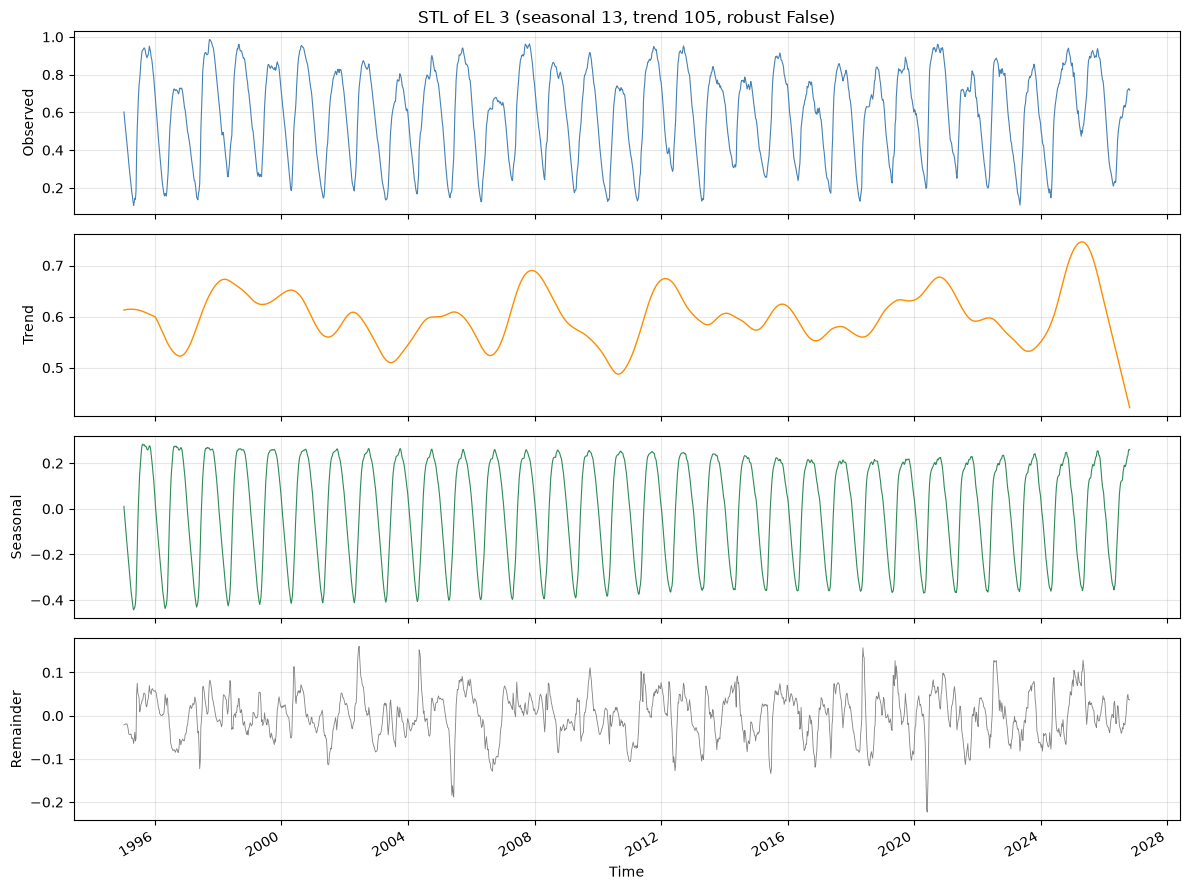

,trend,seasonal,remainder
Date,,,
1995-01-08,0.612903,0.010690,-0.021217
1995-01-15,0.613160,-0.023168,-0.020049
1995-01-22,0.613397,-0.051030,-0.020164
1995-01-29,0.613614,-0.086783,-0.018684
1995-02-05,0.613811,-0.120369,-0.019559


In [18]:
# Default settings on electricity area 3.
figure, parts = reservoir_cycles(reservoirs)
plt.show()

parts.head()

Weeks in series: 1660
Seasonal share of variance: 0.88
Trend share of variance: 0.08
Remainder standard deviation: 0.0401


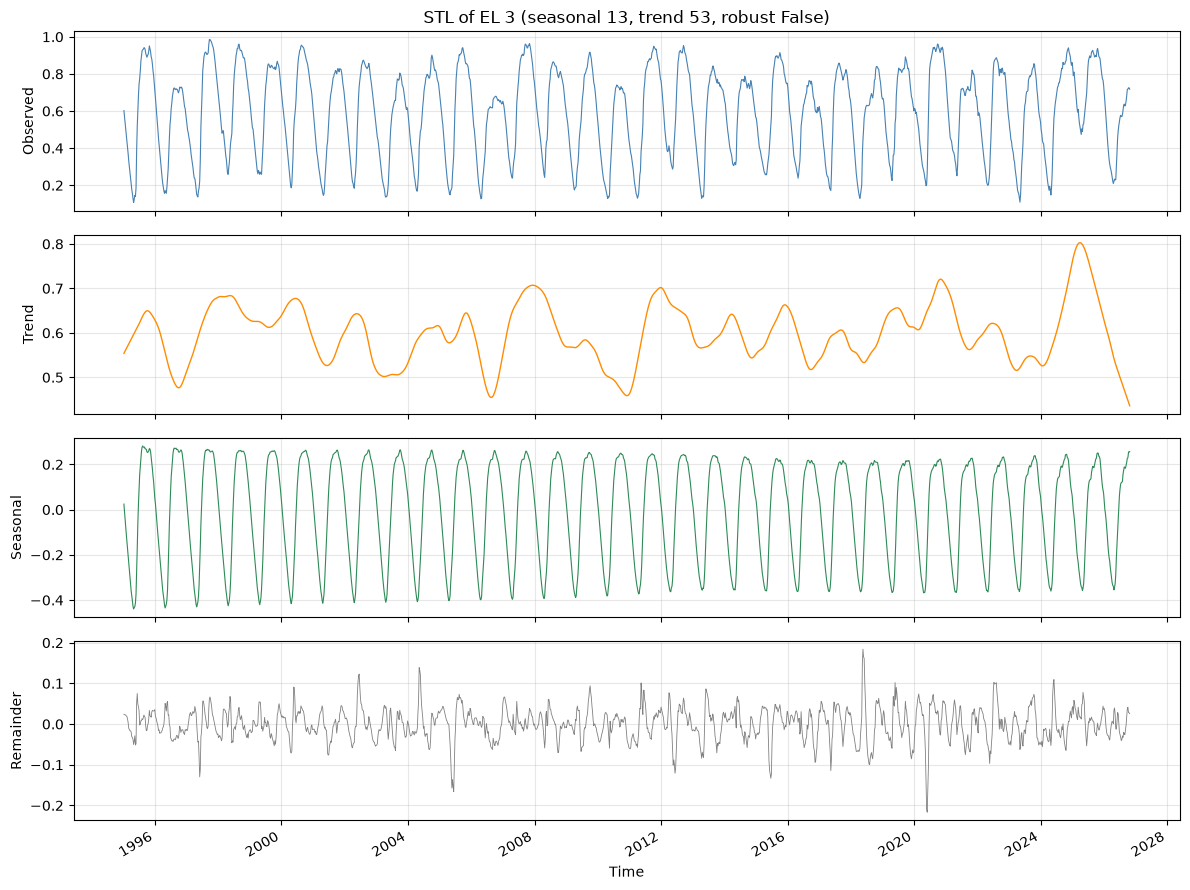

In [19]:
# A shorter trend smoother lets more of the slow movement count as trend.
figure, parts_short = reservoir_cycles(reservoirs, trend_smoother=53)
plt.show()

Weeks in series: 1660
Seasonal share of variance: 0.82
Trend share of variance: 0.10
Remainder standard deviation: 0.0481


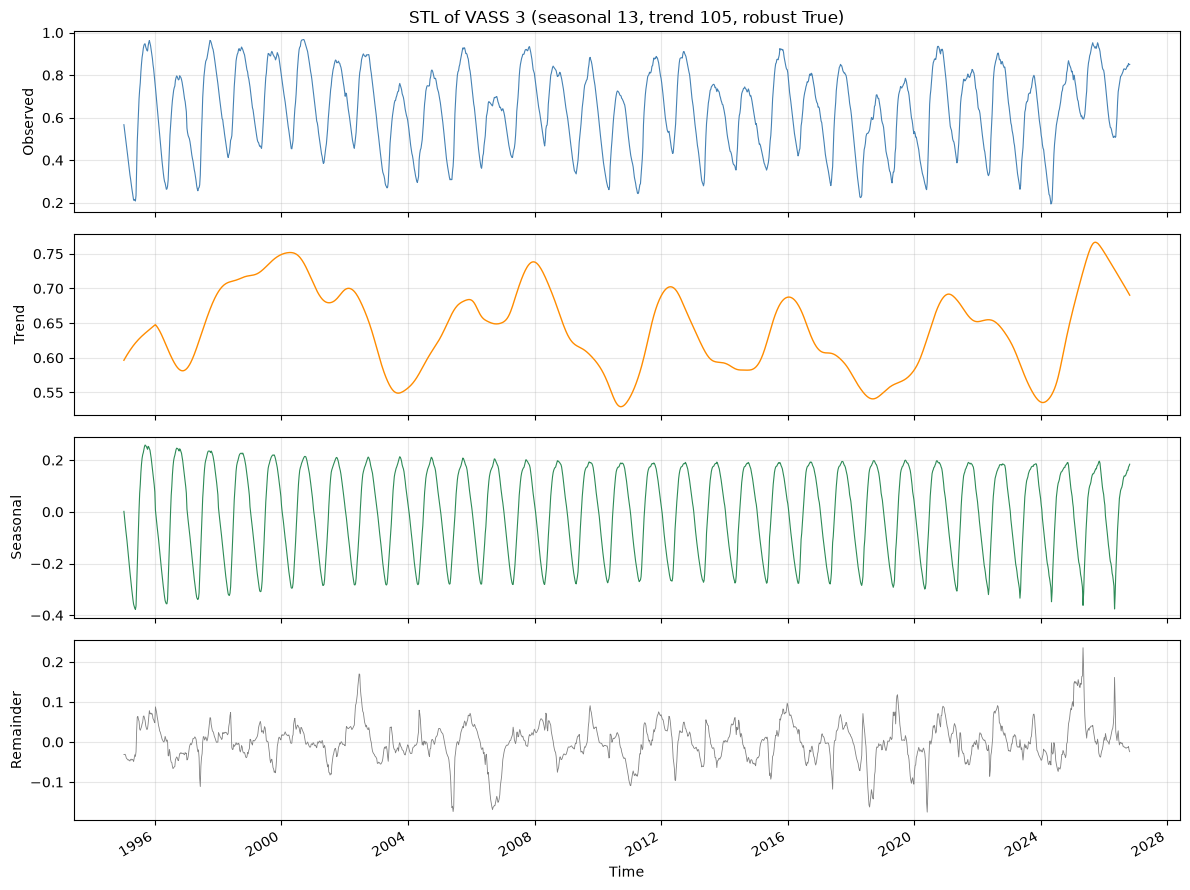

In [20]:
# The same area as a watercourse region instead, with robust turned on.
figure, parts_vass = reservoir_cycles(reservoirs, area_type="VASS",
                                      area_number=3, robust=True)
plt.show()

The season explains 0.88 of the variation in EL 3, which fits a curve that
repeats this clearly every year.

Shortening the trend smoother from 105 to 53 weeks moves movement out of the
remainder and into the trend. The trend share goes from 0.05 to 0.08 and the
remainder standard deviation drops from 0.0517 to 0.0401. Nothing new has been
found, the same variation has only been labelled differently, which is exactly
what that parameter controls.

VASS 3 has a weaker season, 0.82, and a stronger trend, 0.10. A watercourse
area covers more than one price area, so the yearly cycles inside it do not
line up as neatly.

## 8. Spectrogram

STL assumes one season for the whole period. A spectrogram does not. It takes
one window of weeks at a time, so a cycle that appears or disappears shows up
as a band that changes brightness.

Frequencies are easier to read as periods, so the vertical axis is the length
of the cycle in weeks. The yearly cycle sits at 52 weeks.

The window length is how many weeks go into each slice. A long window
separates close periods better, a short one says more precisely when something
changed. The overlap is how much two neighbouring windows share.

In [21]:
def reservoir_spectrogram(reservoirs, area_type="EL", area_number=3,
                          window_weeks=208, overlap_weeks=156,
                          column="Fill level (fraction)"):
    """Show how the cycles in one area's reservoir filling change over time.

    window_weeks is the length of each slice, overlap_weeks is how much two
    neighbouring slices share. The overlap has to be smaller than the window.
    """
    area = reservoirs[(reservoirs["Area type"] == area_type) &
                      (reservoirs["Area number"] == area_number)]
    area = area.sort_values("Date")

    series = area.set_index("Date")[column]
    series = series[~series.index.duplicated(keep="first")]
    values = series.to_numpy()

    # One sample per week, so fs is 1 and the periods come out in weeks.
    frequencies, window_centres, power = spectrogram(
        values, fs=1.0, nperseg=window_weeks, noverlap=overlap_weeks
    )

    # Drop frequency zero, which is only the average level and not a cycle.
    frequencies = frequencies[1:]
    power = power[1:, :]
    periods = 1.0 / frequencies

    # scipy counts the window centres in samples, and one sample is a week.
    times = series.index[0] + pd.to_timedelta(window_centres * 7, unit="D")

    figure, axes = plt.subplots(figsize=(12, 5))

    # Decibels, or the yearly cycle would be the only visible band.
    mesh = axes.pcolormesh(times, periods, 10 * np.log10(power),
                           shading="auto", cmap="magma")

    axes.set_yscale("log")
    axes.set_yticks([8, 13, 26, 52, 104, 208])
    axes.set_yticklabels(["8", "13", "26", "52", "104", "208"])
    axes.set_ylabel("Period (weeks)")
    axes.set_xlabel("Time")
    axes.set_title(
        f"Spectrogram of {area_type} {area_number} "
        f"(window {window_weeks} weeks, overlap {overlap_weeks})"
    )
    figure.colorbar(mesh, ax=axes, label="Power (dB)")
    figure.autofmt_xdate()
    figure.tight_layout()

    # The bin closest to one year, so its strength can be followed separately.
    yearly_bin = int(np.argmin(np.abs(periods - 52)))

    # Pick out the strongest period in each window.
    rows = []
    for window in range(power.shape[1]):
        strongest = int(np.argmax(power[:, window]))
        rows.append({
            "window_centre": times[window],
            "strongest_period_weeks": round(periods[strongest], 1),
            "yearly_power_db": round(
                10 * np.log10(power[yearly_bin, window]), 1
            ),
        })

    summary = pd.DataFrame(rows)

    print(f"Windows: {power.shape[1]}")
    print(f"Periods covered: {periods.min():.1f} to {periods.max():.1f} weeks")

    return figure, summary

Windows: 28
Periods covered: 2.0 to 208.0 weeks


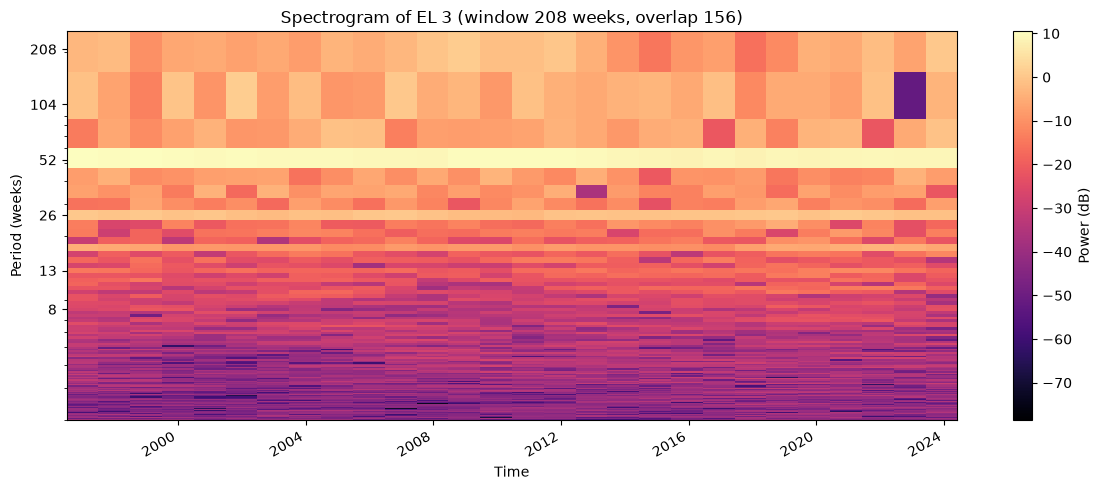

,window_centre,strongest_period_weeks,yearly_power_db
0,1997-01-05,52.0,10.5
1,1998-01-04,52.0,9.9
2,1999-01-03,52.0,10.2
3,2000-01-02,52.0,10.0
4,2000-12-31,52.0,9.8


In [22]:
# Default window of four years.
figure, cycles = reservoir_spectrogram(reservoirs)
plt.show()

cycles.head()

Windows: 60
Periods covered: 2.0 to 104.0 weeks


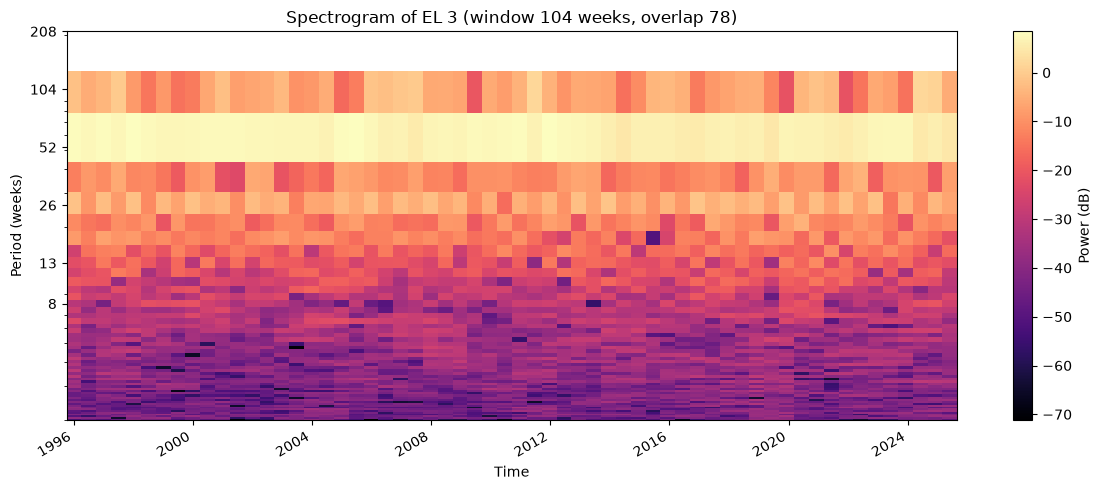

In [23]:
# A shorter window locates changes better but blurs close periods.
figure, short_cycles = reservoir_spectrogram(reservoirs, window_weeks=104,
                                             overlap_weeks=78)
plt.show()

In [24]:
# The strongest cycle in each window, to check that the yearly one dominates.
print("Most common strongest period:")
print(cycles["strongest_period_weeks"].value_counts().head())

Most common strongest period:
strongest_period_weeks
52.0    28
Name: count, dtype: int64


52 weeks is the strongest period in all 28 windows, and its strength stays
around 10 dB from 1997 to 2024. So the yearly cycle has not changed over the
thirty years NVE has published the statistics.

That is a negative result, but a useful one. If the strongest period had moved
or the yearly band had faded, it would have meant the filling pattern itself
was changing, and that is exactly what a spectrogram can show while STL
cannot.

## 9. Log

The first problem was finding the shapefiles. The assignment said to download
the area borders from NVE, but I could not find them in the map service on my
own. I searched for elspot, price area and precipitation without getting
anything useful. Luckily, in Tuesday's lecture, the teacher showed which ones
to use.

NVE has five regions while Magasinstatistikk reports three watercourse areas,
so two pairs of regions have to be merged before sampling. Region Sør and
Region Øst become one, and Region Midt and Region Nord become the other. This
is also why VASS 4 never shows up in the data, which I had noticed in part 2
without understanding why. It was nice to finally get the explanation.

The sampling was straightforward once the files were in place. I draw 1000
random points inside each area, convert them from the UTM coordinates the
shapefiles use to ordinary latitude and longitude, and store them in MongoDB.
That way the app reads the same coordinates without having to install
geopandas or read a shapefile itself.

Open-meteo was a bit tricky at the beginning. I had not understood that the
limit counts how much data you ask for rather than how many requests you send,
and that three separate limits run at the same time. I kept getting 429 and
thought my code was wrong. It was not, but I was asking for too much at once.
The fix was to store every response on disk, so a download that stops on a
limit continues where it left off instead of starting over.

Each of the four analyses is written as a function with its settings as
parameters, so the same method runs in the notebook and in the app. The cosine
transform finds the seasonal shape of the precipitation and the SPC limits are
drawn around it, so the limits follow the season instead of being two straight
lines. Local Outlier Factor marks the share of hours that stand out most from
the hours around them. STL splits the reservoir filling into a trend, a yearly
season and a remainder, and the spectrogram shows whether those cycles change
over the years.

In the app I made the area selector global, since the reservoir pages and the
weather page have to describe the same place. The download control is part of
the weather page instead of a page of its own, because it only appears when an
area has no weather stored yet, and a separate page would be empty almost all
the time.

## 10. AI declaration

Claude (Anthropic) was used for:
- Sparring when structuring the notebook and the app
- Explanations of geopandas, the open-meteo rate limits and the four analyses
- Suggesting and reviewing code

Gemini was used for:
- Concept clarification (shapefiles, coordinate systems, STL and spectrograms)
- Environment setup and troubleshooting on macOS / VS Code
- Assistance for terminal commands

All code was run, tested and adjusted by me. NVE, open-meteo and Streamlit documentation were used as primary
sources.